In [4]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
import pandas as pd

In [6]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from src.utils import *
set_plot_style()
print("setup ok")

setup ok


In [7]:
raw = pd.read_csv(DATA_RAW, parse_dates=["Date"])
df = raw[(raw["City"] == CITY) & raw["Date"].between(WINDOW_START, WINDOW_END)].copy()
df = df.dropna(subset=POLLUTANTS + ["AQI"])
df["Month"] = df["Date"].dt.month
df["Season"] = df["Month"].map(season_of)
df["Poor_Flag"] = df["AQI"].map(poor_flag)
print(df.shape)
print(df["Poor_Flag"].value_counts(normalize=True).round(3))

(1698, 19)
Poor_Flag
1    0.723
0    0.277
Name: proportion, dtype: float64


In [8]:
season_d = pd.get_dummies(df["Season"]).drop(columns="Winter").astype(float)
X = pd.concat([df[POLLUTANTS], season_d], axis=1)
y = df["Poor_Flag"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE,
                                          random_state=SEED, stratify=y)

logit = sm.Logit(y_tr, sm.add_constant(X_tr)).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:              Poor_Flag   No. Observations:                 1358
Model:                          Logit   Df Residuals:                     1345
Method:                           MLE   Df Model:                           12
Date:                Mon, 12 Oct 2026   Pseudo R-squ.:                  0.7418
Time:                        10:05:31   Log-Likelihood:                -207.13
converged:                       True   LL-Null:                       -802.15
Covariance Type:            nonrobust   LLR p-value:                2.408e-247
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const          -11.7529      1.198     -9.812      0.000     -14.101      -9.405
PM2.5            0.0526      0.010      5.386      0.000       0.033       0.072
PM10             0.0280      0.003      8.46

In [9]:
p_te = logit.predict(sm.add_constant(X_te))
pred_te = (p_te >= 0.5).astype(int)
print(pd.DataFrame(confusion_matrix(y_te, pred_te),
                   index=["Actual not Poor", "Actual Poor"],
                   columns=["Pred not Poor", "Pred Poor"]))
m = classification_metrics(y_te, pred_te, p_te)
m["Gini"] = 2 * m["ROC_AUC"] - 1
print({k: round(v, 3) for k, v in m.items()})

                 Pred not Poor  Pred Poor
Actual not Poor             76         18
Actual Poor                 13        233
{'Accuracy': 0.909, 'Precision': 0.928, 'Recall': 0.947, 'F1': 0.938, 'ROC_AUC': 0.961, 'Gini': 0.921}


In [10]:
print(f"Share of Poor days in test set: {y_te.mean():.3f}")

Share of Poor days in test set: 0.724


In [11]:
def hosmer_lemeshow(y_true, p_hat, g=10):
    d = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(p_hat)})
    d["bin"] = pd.qcut(d["p"], g, duplicates="drop")
    t = d.groupby("bin", observed=True).agg(n=("y", "size"), obs=("y", "sum"), exp=("p", "sum"))
    t["obs0"], t["exp0"] = t["n"] - t["obs"], t["n"] - t["exp"]
    eps = 1e-9
    stat = (((t["obs"] - t["exp"]) ** 2 / (t["exp"] + eps)) +
            ((t["obs0"] - t["exp0"]) ** 2 / (t["exp0"] + eps))).sum()
    dof = len(t) - 2
    return stat, dof, 1 - stats.chi2.cdf(stat, dof), t

hl_stat, hl_dof, hl_p, hl_table = hosmer_lemeshow(y_tr, logit.predict(sm.add_constant(X_tr)))
print(f"Hosmer-Lemeshow: chi2 = {hl_stat:.2f}, df = {hl_dof}, p = {hl_p:.3f}")
hl_table.round(2)

Hosmer-Lemeshow: chi2 = 15.30, df = 8, p = 0.053


,n,obs,exp,obs0,exp0
bin,,,,,
"(5.6607579e-05, 0.015056907]",136,0,0.58,136,135.42
"(0.015056907, 0.15325283]",136,11,8.90,125,127.10
"(0.15325283, 0.63893184]",136,49,53.35,87,82.65
"(0.63893184, 0.91359865]",135,110,108.66,25,26.34
"(0.91359865, 0.98938824]",136,135,131.13,1,4.87
"(0.98938824, 0.99908856]",136,133,135.43,3,0.57
"(0.99908856, 0.99993677]",135,135,134.96,0,0.04
"(0.99993677, 0.99999784]",136,136,136.00,0,0.00
"(0.99999784, 0.99999998]",136,136,136.00,0,0.00


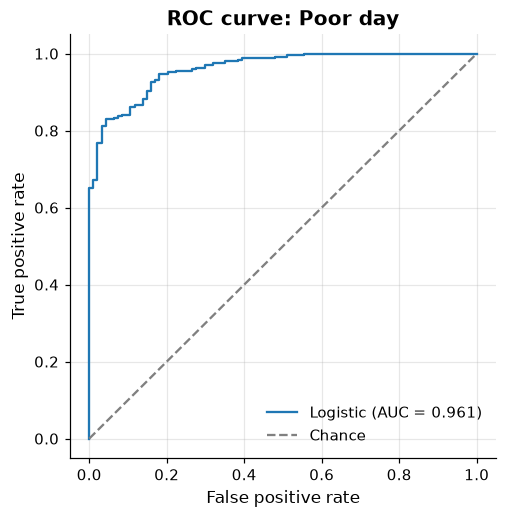

In [12]:
fpr, tpr, _ = roc_curve(y_te, p_te)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, label=f"Logistic (AUC = {roc_auc_score(y_te, p_te):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Chance")
ax.set(title="ROC curve: Poor day", xlabel="False positive rate", ylabel="True positive rate")
ax.legend()
plt.show()

In [13]:
orr = np.exp(pd.concat([logit.params, logit.conf_int()], axis=1))
orr.columns = ["Odds ratio", "2.5%", "97.5%"]
orr.drop("const").round(3)

,Odds ratio,2.5%,97.5%
PM2.5,1.054,1.034,1.074
PM10,1.028,1.022,1.035
NO,0.992,0.964,1.020
NO2,0.973,0.941,1.006
NOx,1.028,1.017,1.038
NH3,1.028,0.996,1.062
CO,1.920,1.592,2.315
SO2,1.025,0.970,1.083
O3,1.040,1.020,1.060
Monsoon,0.296,0.090,0.971


In [14]:
clf_results = [{"Model": "Logistic regression", **m}]